# Proyek Machine Learning: Prediksi Persetujuan Pinjaman (Loan Approval)

## 1. Data Understanding & Setup
Bagian ini memuat konfigurasi lingkungan kerja, import pustaka utama untuk manipulasi dan visualisasi data, serta inspeksi struktur awal dataset.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    ConfusionMatrixDisplay
)

# Supresi peringatan non-kritis agar notebook tetap rapi
warnings.filterwarnings('ignore')

# Konfigurasi tampilan Pandas agar seluruh kolom finansial terlihat
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

# Konfigurasi visualisasi default
plt.style.use('seaborn-v0_8-whitegrid') if 'seaborn-v0_8-whitegrid' in plt.style.available else plt.style.use('default')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['figure.dpi'] = 100

# Kunci seed agar hasil split dan pemodelan selalu konsisten
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Pustaka dan konfigurasi lingkungan kerja berhasil disiapkan.")

Pustaka dan konfigurasi lingkungan kerja berhasil disiapkan.


In [2]:
DATA_PATH = 'Loan Dataset.csv'
df = pd.read_csv(DATA_PATH)

print(f"Dimensi Dataset: {df.shape[0]:,} baris dan {df.shape[1]} kolom\n")
display(df.head(5))

# Tinjau ringkasan tipe data dan memori
df.info()

Dimensi Dataset: 52,000 baris dan 27 kolom



,Applicant_ID,Gender,Age,Marital_Status,Dependents,Education,Employment_Status,Occupation_Type,Residential_Status,City/Town,Annual_Income,Monthly_Expenses,Credit_Score,Existing_Loans,Total_Existing_Loan_Amount,Outstanding_Debt,Loan_History,Loan_Amount_Requested,Loan_Term,Loan_Purpose,Interest_Rate,Loan_Type,Co-Applicant,Bank_Account_History,Transaction_Frequency,Default_Risk,Loan_Approval_Status
0,1,Female,25,Married,2,Graduate,Employed,Business,Own,Urban,139901,2533,743,0,10942,19822,0,24535,209,Home,4.270,Secured,Yes,8,20,0.810,1
1,2,Male,36,Married,2,High School,Employed,Business,Own,Suburban,21162,4041,468,1,48731,18321,0,8288,33,Home,14.780,Unsecured,Yes,9,9,0.170,0
2,3,Male,43,Single,0,Postgraduate,Self-Employed,Freelancer,Own,Urban,27815,3453,389,2,6925,13851,0,10308,159,Vehicle,12.330,Secured,Yes,7,27,0.250,0
3,4,Female,28,Married,0,High School,Self-Employed,Freelancer,Rent,Suburban,137853,2732,778,0,42016,28608,1,33937,39,Personal,8.770,Secured,No,9,16,0.270,1
4,5,Female,32,Single,0,Graduate,Employed,Salaried,Rent,Suburban,81753,1648,752,2,31747,8780,1,23360,34,Home,9.040,Unsecured,No,1,17,0.320,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52000 entries, 0 to 51999
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Applicant_ID                52000 non-null  int64  
 1   Gender                      52000 non-null  object 
 2   Age                         52000 non-null  int64  
 3   Marital_Status              52000 non-null  object 
 4   Dependents                  52000 non-null  int64  
 5   Education                   52000 non-null  object 
 6   Employment_Status           52000 non-null  object 
 7   Occupation_Type             52000 non-null  object 
 8   Residential_Status          52000 non-null  object 
 9   City/Town                   52000 non-null  object 
 10  Annual_Income               52000 non-null  int64  
 11  Monthly_Expenses            52000 non-null  int64  
 12  Credit_Score                52000 non-null  int64  
 13  Existing_Loans              520

## 2. Exploratory Data Analysis (EDA) & Interpretasi Visualisasi
Eksplorasi visual dan analisis statistik untuk memahami distribusi kelas target, korelasi antarfitur finansial, driver utama keputusan kredit, serta bentuk distribusi prediktor.

Distribusi Target Class:


,Jumlah,Persentase (%)
Loan_Approval_Status,,
1,33366,64.165
0,18634,35.835


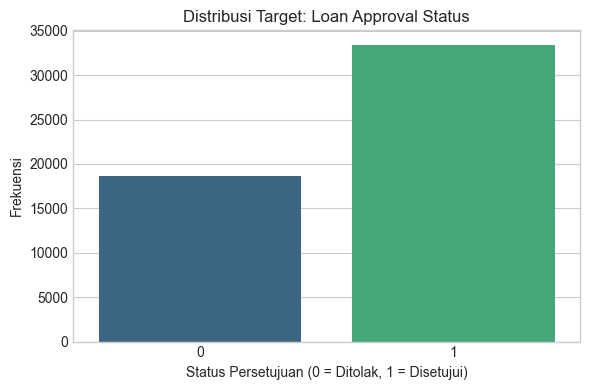

In [3]:
# Analisis distribusi kelas target
target_col = 'Loan_Approval_Status'
target_counts = df[target_col].value_counts()
target_pct = df[target_col].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({'Jumlah': target_counts, 'Persentase (%)': target_pct})
print("Distribusi Target Class:")
display(target_summary)

# Visualisasi countplot distribusi target
plt.figure(figsize=(6, 4))
sns.countplot(x=target_col, data=df, palette='viridis')
plt.title('Distribusi Target: Loan Approval Status')
plt.xlabel('Status Persetujuan (0 = Ditolak, 1 = Disetujui)')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

### Interpretasi Visualisasi 2.1: Distribusi Target & Class Imbalance
- **Proporsi Kelas:** Dataset memiliki 33.366 data disetujui (64.17%) dan 18.634 data ditolak (35.83%).
- **Indikasi Imbalance:** Terdapat ketimpangan kelas tingkat moderat (~64:36). Model naif (majority baseline) yang selalu memprediksi status 'Disetujui' akan memperoleh akurasi semu 64.17%.
- **Dampak Pemodelan:** Akurasi tunggal tidak dapat dijadikan tolok ukur keandalan model. Metrik evaluasi wajib difokuskan pada ROC-AUC, F1-Score, dan Recall pada kelas 0 (Ditolak) untuk mencegah risiko nasabah macet yang tidak terdeteksi. Split data juga harus menggunakan stratifikasi (`stratify=y`).

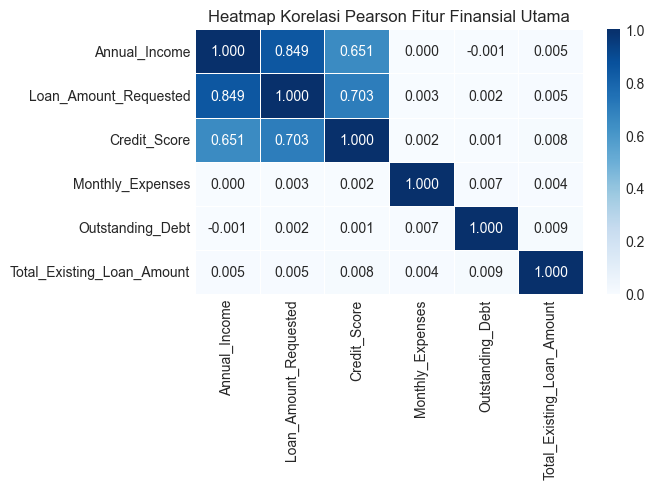

In [4]:
# Analisis multikolinearitas pada fitur finansial utama
fokus_fitur = [
    'Annual_Income',
    'Loan_Amount_Requested',
    'Credit_Score',
    'Monthly_Expenses',
    'Outstanding_Debt',
    'Total_Existing_Loan_Amount'
]

plt.figure(figsize=(7, 5))
sns.heatmap(df[fokus_fitur].corr(), annot=True, cmap='Blues', fmt='.3f', linewidths=0.5)
plt.title('Heatmap Korelasi Pearson Fitur Finansial Utama')
plt.tight_layout()
plt.show()

### Interpretasi Visualisasi 2.2: Korelasi Antarfitur Finansial
- **Multikolinearitas Tinggi:** Ditemukan korelasi linear yang sangat kuat antara `Loan_Amount_Requested` dan `Annual_Income` (r = 0.849), serta `Credit_Score` dengan `Loan_Amount_Requested` (r = 0.703) dan `Annual_Income` (r = 0.651).
- **Logika Bisnis:** Pemohon dengan pendapatan dan skor kredit yang tinggi cenderung mengajukan pinjaman dengan nominal plafon yang jauh lebih besar.
- **Dampak Pemodelan:** Tingginya multikolinearitas dapat mendistorsi koefisien pada model regresi linear biasa. Namun, hubungan ini menjadi landasan kuat untuk membuat fitur rasio finansial baru (seperti rasio pinjaman terhadap pendapatan / LTI).

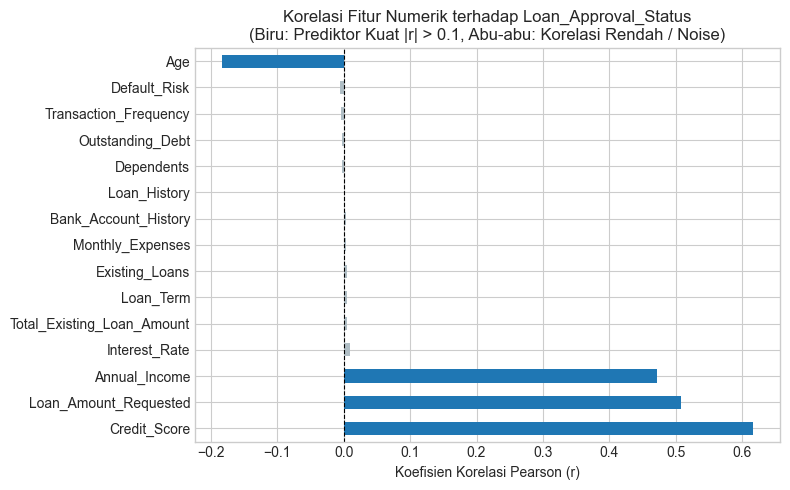

Koefisien Korelasi terhadap Target:
Credit_Score                  0.617
Loan_Amount_Requested         0.508
Annual_Income                 0.472
Interest_Rate                 0.009
Total_Existing_Loan_Amount    0.006
Loan_Term                     0.005
Existing_Loans                0.004
Monthly_Expenses              0.004
Bank_Account_History          0.004
Loan_History                  0.001
Dependents                   -0.003
Outstanding_Debt             -0.003
Transaction_Frequency        -0.003
Default_Risk                 -0.005
Age                          -0.184
dtype: float64


In [5]:
# Analisis kekuatan korelasi seluruh fitur numerik terhadap target
ignore_cols = ['Applicant_ID', target_col]
num_cols = [c for c in df.select_dtypes(include=['int64', 'float64']).columns if c not in ignore_cols]

corr_target = df[num_cols].apply(lambda x: df[target_col].corr(x)).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
colors = ['#1f77b4' if abs(x) > 0.1 else '#b0bec5' for x in corr_target.values]
corr_target.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Korelasi Fitur Numerik terhadap Loan_Approval_Status\n(Biru: Prediktor Kuat |r| > 0.1, Abu-abu: Korelasi Rendah / Noise)')
plt.xlabel('Koefisien Korelasi Pearson (r)')
plt.tight_layout()
plt.show()

print("Koefisien Korelasi terhadap Target:")
print(corr_target.round(4))

### Interpretasi Visualisasi 2.3: Driver Utama Persetujuan Kredit
- **Prediktor Positif Dominan:** Credit_Score (r = 0.617), Loan_Amount_Requested (r = 0.508), dan Annual_Income (r = 0.472) merupakan faktor penentu kelayakan pinjaman yang paling kuat. Nasabah dengan riwayat kredit solid dan kapasitas pendapatan tinggi memiliki peluang persetujuan pinjaman yang jauh lebih besar.
- **Prediktor Negatif Nyata:** Age (r = -0.184) berkorelasi negatif signifikan dengan status persetujuan, mengindikasikan bahwa pemohon berusia lebih tua memiliki tingkat penolakan yang lebih tinggi dalam pola dataset ini.
- **Fitur Non-Prediktif (Noise):** Berlawanan dengan intuisi perbankan konvensional, fitur mentah Interest_Rate (r = 0.009) dan Default_Risk (r = -0.005) memiliki korelasi linear mendekati nol terhadap target. Demikian pula variabel demografi seperti jumlah tanggungan (r = -0.003) dan frekuensi transaksi (r = -0.003), yang mengonfirmasi karakteristik sintetis dataset.

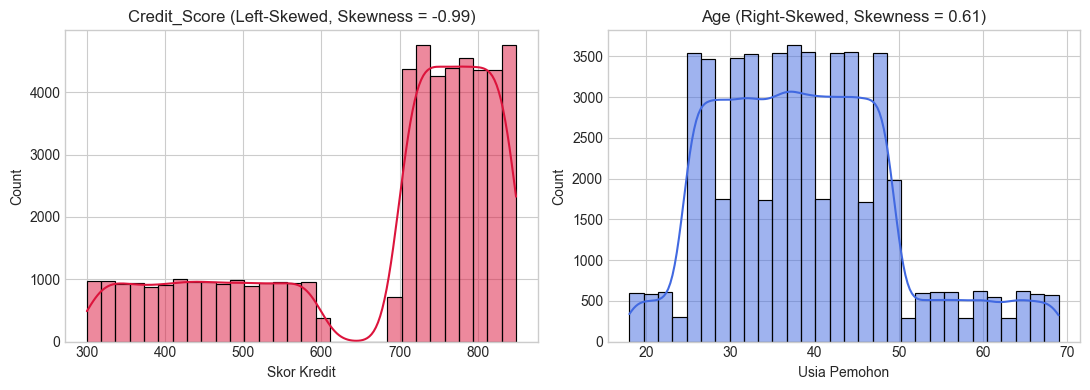

In [6]:
# Analisis bentuk distribusi dan kemiringan (skewness)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(df['Credit_Score'], kde=True, color='crimson', bins=30, ax=axes[0])
axes[0].set_title(f"Credit_Score (Left-Skewed, Skewness = {df['Credit_Score'].skew():.2f})")
axes[0].set_xlabel("Skor Kredit")

sns.histplot(df['Age'], kde=True, color='royalblue', bins=30, ax=axes[1])
axes[1].set_title(f"Age (Right-Skewed, Skewness = {df['Age'].skew():.2f})")
axes[1].set_xlabel("Usia Pemohon")

plt.tight_layout()
plt.show()

### Interpretasi Visualisasi 2.4: Bentuk Distribusi & Kemiringan (Skewness)
- **Credit_Score (Miring Kiri, Skewness = -0.99):** Mayoritas data pemohon berkumpul pada skor kredit yang relatif tinggi (> 600) dengan ekor memanjang ke arah nilai rendah. Ini mencerminkan profil nasabah bank yang sebagian besar memiliki riwayat kredit aktif.
- **Age (Miring Kanan, Skewness = +0.61):** Populasi pemohon didominasi oleh kelompok usia muda hingga dewasa produktif (20-40 tahun).
- **Implikasi Scaling:** Distribusi yang tidak simetris dan memiliki rentang magnitude yang berbeda-beda memerlukan tahapan standardisasi (StandardScaler) agar algoritma berbasis gradient descent dapat mengonvergenkan bobot secara optimal.

## 3. Data Quality Findings (Temuan Anomali & Kualitas Data)
Pemeriksaan sistematis terhadap integritas teknis dataset (missing value, duplikasi, identifier), disparitas skala, kategori, deteksi outlier, serta audit anomali logika bisnis demografi (temuan indikasi data sintetis seperti pada referensi Vera.ipynb).

In [7]:
# 1. Pengecekan Missing Value
missing_series = df.isnull().sum()
print("=== Temuan 1: Pemeriksaan Missing Value ===")
print(missing_series[missing_series > 0] if missing_series.sum() > 0 else "Tidak ada missing value (0 null pada seluruh kolom dataset).")

# 2. Pengecekan Data Duplikat
full_duplicates = df.duplicated().sum()
duplicates_no_id = df.drop(columns=['Applicant_ID']).duplicated().sum()
print("\n=== Temuan 2: Pemeriksaan Duplikasi Baris ===")
print(f"Baris duplikat penuh: {full_duplicates}")
print(f"Baris duplikat (tanpa kolom ID): {duplicates_no_id}")

# 3. Analisis Kolom Identifier (Applicant_ID)
n_unique_id = df['Applicant_ID'].nunique()
id_corr = df['Applicant_ID'].corr(df[target_col])
print("\n=== Temuan 3: Karakteristik Kolom Identifier (Applicant_ID) ===")
print(f"Jumlah nilai unik: {n_unique_id:,} dari {len(df):,} total baris (100% unik).")
print(f"Korelasi Pearson dengan target: {id_corr:.4f} (noise acak, wajib dibuang dari fitur).")

=== Temuan 1: Pemeriksaan Missing Value ===
Tidak ada missing value (0 null pada seluruh kolom dataset).

=== Temuan 2: Pemeriksaan Duplikasi Baris ===
Baris duplikat penuh: 0
Baris duplikat (tanpa kolom ID): 0

=== Temuan 3: Karakteristik Kolom Identifier (Applicant_ID) ===
Jumlah nilai unik: 52,000 dari 52,000 total baris (100% unik).
Korelasi Pearson dengan target: -0.0019 (noise acak, wajib dibuang dari fitur).


In [8]:
# 4. Analisis Disparitas Skala Fitur Numerik
skala_df = pd.DataFrame({
    'Nilai Min': df[num_cols].min(),
    'Nilai Max': df[num_cols].max(),
    'Rentang (Max - Min)': df[num_cols].max() - df[num_cols].min()
}).sort_values(by='Nilai Max', ascending=False)

def kategori_skala(val):
    if val >= 10000:
        return 'Puluhan / Ratusan Ribu'
    elif val >= 100:
        return 'Ratusan'
    else:
        return 'Puluhan / Satuan'

skala_df['Kelompok Skala'] = skala_df['Nilai Max'].apply(kategori_skala)
print("=== Temuan 4: Disparitas Skala Antarfitur Numerik ===")
display(skala_df)

=== Temuan 4: Disparitas Skala Antarfitur Numerik ===


,Nilai Min,Nilai Max,Rentang (Max - Min),Kelompok Skala
Annual_Income,20009.000,149998.000,129989.000,Puluhan / Ratusan Ribu
Total_Existing_Loan_Amount,0.000,49999.000,49999.000,Puluhan / Ratusan Ribu
Loan_Amount_Requested,5000.000,44848.000,39848.000,Puluhan / Ratusan Ribu
Outstanding_Debt,0.000,29998.000,29998.000,Puluhan / Ratusan Ribu
Monthly_Expenses,500.000,4999.000,4499.000,Ratusan
Credit_Score,300.000,849.000,549.000,Ratusan
Loan_Term,12.000,239.000,227.000,Ratusan
Age,18.000,69.000,51.000,Puluhan / Satuan
Transaction_Frequency,5.000,29.000,24.000,Puluhan / Satuan
Interest_Rate,3.500,15.000,11.500,Puluhan / Satuan


In [9]:
# 5. Analisis Fitur Kategorikal
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
cat_summary = []

for col in cat_cols:
    unique_vals = df[col].unique().tolist()
    n_unique = len(unique_vals)
    kategori = 'Biner (2 nilai)' if n_unique == 2 else f'Multikelas ({n_unique} nilai)'
    cat_summary.append({
        'Nama Kolom': col,
        'Jumlah Kategori': n_unique,
        'Kelompok': kategori,
        'Daftar Nilai Kategori': ', '.join(map(str, unique_vals))
    })

cat_df = pd.DataFrame(cat_summary)
print(f"=== Temuan 5: Struktur {len(cat_cols)} Fitur Kategorikal ===")
display(cat_df)

print("\nRincian:")
print(f"- Fitur Biner: {cat_df[cat_df['Jumlah Kategori'] == 2]['Nama Kolom'].tolist()}")
print(f"- Fitur Multikelas: {cat_df[cat_df['Jumlah Kategori'] > 2]['Nama Kolom'].tolist()}")

=== Temuan 5: Struktur 10 Fitur Kategorikal ===


,Nama Kolom,Jumlah Kategori,Kelompok,Daftar Nilai Kategori
0,Gender,2,Biner (2 nilai),"Female, Male"
1,Marital_Status,3,Multikelas (3 nilai),"Married, Single, Divorced"
2,Education,3,Multikelas (3 nilai),"Graduate, High School, Postgraduate"
3,Employment_Status,3,Multikelas (3 nilai),"Employed, Self-Employed, Unemployed"
4,Occupation_Type,4,Multikelas (4 nilai),"Business, Freelancer, Salaried, Professional"
5,Residential_Status,3,Multikelas (3 nilai),"Own, Rent, Other"
6,City/Town,3,Multikelas (3 nilai),"Urban, Suburban, Rural"
7,Loan_Purpose,4,Multikelas (4 nilai),"Home, Vehicle, Personal, Education"
8,Loan_Type,2,Biner (2 nilai),"Secured, Unsecured"
9,Co-Applicant,2,Biner (2 nilai),"Yes, No"



Rincian:
- Fitur Biner: ['Gender', 'Loan_Type', 'Co-Applicant']
- Fitur Multikelas: ['Marital_Status', 'Education', 'Employment_Status', 'Occupation_Type', 'Residential_Status', 'City/Town', 'Loan_Purpose']


=== Temuan 6: Rekapitulasi Deteksi Outlier (Metode IQR) ===


,Fitur,Q1,Q3,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%)
0,Age,31.000,45.000,10.000,66.000,862,1.66%
1,Loan_Amount_Requested,16941.750,25809.000,3640.880,39109.880,896,1.72%


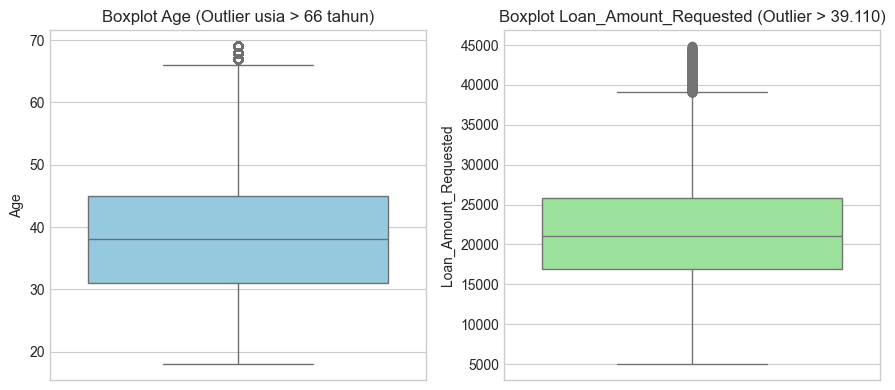

In [10]:
# 6. Deteksi Outlier Menggunakan Metode IQR (1.5x)
fitur_kontinu = [
    'Age',
    'Loan_Amount_Requested',
    'Annual_Income',
    'Monthly_Expenses',
    'Credit_Score',
    'Total_Existing_Loan_Amount',
    'Outstanding_Debt',
    'Interest_Rate'
]

outlier_list = []
for col in fitur_kontinu:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    n_outliers = len(outliers)
    pct_outliers = (n_outliers / len(df)) * 100

    outlier_list.append({
        'Fitur': col,
        'Q1': round(q1, 2),
        'Q3': round(q3, 2),
        'Batas Bawah': round(lower_bound, 2),
        'Batas Atas': round(upper_bound, 2),
        'Jumlah Outlier': n_outliers,
        'Persentase (%)': f'{pct_outliers:.2f}%'
    })

outlier_df = pd.DataFrame(outlier_list)
print("=== Temuan 6: Rekapitulasi Deteksi Outlier (Metode IQR) ===")
display(outlier_df[outlier_df['Jumlah Outlier'] > 0])

# Visualisasi boxplot untuk fitur yang memiliki outlier
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
sns.boxplot(y=df['Age'], color='skyblue', ax=axes[0])
axes[0].set_title('Boxplot Age (Outlier usia > 66 tahun)')

sns.boxplot(y=df['Loan_Amount_Requested'], color='lightgreen', ax=axes[1])
axes[1].set_title('Boxplot Loan_Amount_Requested (Outlier > 39.110)')

plt.tight_layout()
plt.show()

In [11]:
# 7. Pemeriksaan Anomali Logika Bisnis & Demografi (Temuan Kunci Indikasi Data Sintetis)
print("=== Temuan 7: Pemeriksaan Anomali Logika Domain Dataset ===\n")

# Kasus 1: Utang tanpa riwayat pinjaman aktif
c1_total = (df['Existing_Loans'] == 0).sum()
c1_anomali = ((df['Existing_Loans'] == 0) & ((df['Total_Existing_Loan_Amount'] > 0) | (df['Outstanding_Debt'] > 0))).sum()
print(f"1. Existing_Loans == 0 tetapi memiliki saldo utang/plafon : {c1_anomali:,} dari {c1_total:,} pemohon ({c1_anomali / c1_total * 100:.2f}%)")

# Kasus 2: Sisa utang melebihi plafon pinjaman awal
c2 = (df['Outstanding_Debt'] > df['Total_Existing_Loan_Amount']).sum()
print(f"2. Sisa Utang Melebihi Plafon Pinjaman (Debt > Loan Amount) : {c2:,} baris ({c2 / len(df) * 100:.2f}%)")

# Kasus 3: Defisit pengeluaran tahunan melebihi pendapatan tahunan
c3 = (df['Monthly_Expenses'] * 12 > df['Annual_Income']).sum()
print(f"3. Defisit Arus Kas (Pengeluaran Tahunan > Pendapatan)       : {c3:,} baris ({c3 / len(df) * 100:.2f}%)")

# Kasus 4: Pengangguran tapi memiliki tipe pekerjaan formal
c4_total = (df['Employment_Status'] == 'Unemployed').sum()
c4_anomali = ((df['Employment_Status'] == 'Unemployed') & (df['Occupation_Type'].isin(['Salaried', 'Professional', 'Business', 'Freelancer']))).sum()
print(f"4. Status Unemployed tetapi punya Occupation_Type formal    : {c4_anomali:,} dari {c4_total:,} orang ({c4_anomali / c4_total * 100:.1f}%)")

# Kasus 5: Anomali Demografi Usia Muda
c5_edu = ((df['Age'] <= 21) & (df['Education'] == 'Postgraduate')).sum()
c5_dep = ((df['Age'] < 20) & (df['Dependents'] >= 2)).sum()
print(f"5. Anomali Demografi (Usia <= 21 bergelar S2: {c5_edu} orang, Usia < 20 tanggungan >= 2: {c5_dep} orang)")

=== Temuan 7: Pemeriksaan Anomali Logika Domain Dataset ===

1. Existing_Loans == 0 tetapi memiliki saldo utang/plafon : 17,350 dari 17,350 pemohon (100.00%)
2. Sisa Utang Melebihi Plafon Pinjaman (Debt > Loan Amount) : 15,618 baris (30.03%)
3. Defisit Arus Kas (Pengeluaran Tahunan > Pendapatan)       : 4,836 baris (9.30%)
4. Status Unemployed tetapi punya Occupation_Type formal    : 10,376 dari 10,376 orang (100.0%)
5. Anomali Demografi (Usia <= 21 bergelar S2: 216 orang, Usia < 20 tanggungan >= 2: 307 orang)


### Rangkuman Temuan Kualitas Data
1. **Bersih Secara Sintaksis:** Dataset memiliki 0 missing value dan 0 baris duplikat penuh dari total 52.000 data.
2. **Kolom Identifier Murni:** Applicant_ID bernilai 100% unik dengan korelasi r = -0.0019 terhadap target sehingga wajib dibuang dari proses pemodelan.
3. **Disparitas Skala Ekstrem:** Nilai fitur bervariasi dari puluhan/ratusan ribu (Annual_Income mencapai 149.998) hingga angka satuan/desimal (Interest_Rate dan Default_Risk), membuktikan pentingnya standardisasi skala.
4. **Outlier Metode IQR:** Ditemukan outlier pada Age sebanyak 862 data (1.66%, usia > 66 tahun) dan Loan_Amount_Requested sebanyak 896 data (1.72%, plafon > 39.110).
5. **Anomali Logika Bisnis (Bukti Kuat Data Sintetis):**
   - 17.350 dari 17.350 pemohon (100%) dengan Existing_Loans == 0 tercatat memiliki saldo utang atau plafon pinjaman aktif.
   - 15.618 baris (30.03%) memiliki sisa utang melebihi plafon pinjaman awal (Outstanding_Debt > Total_Existing_Loan_Amount).
   - 4.836 baris (9.30%) mengalami defisit arus kas tahunan (Monthly_Expenses * 12 > Annual_Income).
   - 10.376 dari 10.376 pemohon (100%) berstatus Unemployed tercatat memiliki Occupation_Type formal ('Salaried', 'Professional', 'Business').

## 4. Preprocessing Plan
Berdasarkan temuan EDA dan kualitas data di atas, strategi preprocessing dirancang sebagai berikut:
1. **Eliminasi ID:** Menghapus `Applicant_ID` dari matriks prediktor $X$ sebelum proses modeling.
2. **Imputasi Protektif:** Memasang `SimpleImputer` dengan strategi `median` untuk fitur numerik dan `most_frequent` untuk fitur kategorikal untuk menjamin kekokohan pipeline saat menerima data baru di masa depan.
3. **Standardisasi Skala:** Menerapkan `StandardScaler` pada seluruh fitur numerik untuk menyamakan magnitude dan mempercepat konvergensi algoritma.
4. **Encoding Kategorikal:** Mengonversi 10 fitur kategorikal dengan `OneHotEncoder(handle_unknown='ignore')` agar aman dari kategori baru yang belum pernah muncul di data latih.
5. **Pencegahan Data Leakage:** Semua proses fitting transformator dibatasi secara ketat hanya pada data latih (`X_train`) menggunakan Scikit-Learn `Pipeline` dan `ColumnTransformer`.
6. **Validasi Terstratifikasi:** Menggunakan `train_test_split` dengan `stratify=y` agar proporsi kelas persetujuan kredit (~64:36) terjaga seimbang di train set dan test set.

## 5. Initial Feature Engineering
Menciptakan fitur-fitur baru berbasis domain perbankan untuk menangkap kapasitas pembayaran riil, rasio beban cicilan, dan interaksi skor risiko pemohon.

In [12]:
# Buat salinan dataframe untuk rekayasa fitur
df_fe = df.copy()

# 1. Debt-to-Income (DTI): Beban utang berjalan terhadap penghasilan tahunan
df_fe['Debt_to_Income_Ratio'] = df_fe['Outstanding_Debt'] / (df_fe['Annual_Income'] + 1)

# 2. Loan-to-Income (LTI): Rasio plafon pinjaman yang diajukan terhadap penghasilan tahunan
df_fe['Loan_to_Income_Ratio'] = df_fe['Loan_Amount_Requested'] / (df_fe['Annual_Income'] + 1)

# 3. Expense-to-Income: Proporsi pengeluaran hidup tahunan terhadap penghasilan tahunan
df_fe['Expense_to_Income_Ratio'] = (df_fe['Monthly_Expenses'] * 12) / (df_fe['Annual_Income'] + 1)

# 4. Sisa Pendapatan Bebas Bulanan (Monthly Disposable Income)
df_fe['Monthly_Disposable_Income'] = (df_fe['Annual_Income'] / 12) - df_fe['Monthly_Expenses']

# 5. Estimasi Cicilan Bulanan Pinjaman Baru (Simple Amortization Estimate)
total_bunga_pinjaman = df_fe['Loan_Amount_Requested'] * (1 + (df_fe['Interest_Rate'] / 100) * (df_fe['Loan_Term'] / 12))
df_fe['Estimated_Monthly_Installment'] = total_bunga_pinjaman / df_fe['Loan_Term']

# 6. Rasio Beban Cicilan Baru terhadap Pendapatan Tahunan
df_fe['Installment_to_Income_Ratio'] = (df_fe['Estimated_Monthly_Installment'] * 12) / (df_fe['Annual_Income'] + 1)

# 7. Indikator Defisit Arus Kas (Pengeluaran > Pendapatan)
df_fe['Is_Financial_Deficit'] = ((df_fe['Monthly_Expenses'] * 12) > df_fe['Annual_Income']).astype(int)

# 8. Rasio Utilisasi Utang terhadap Total Plafon Lama
df_fe['Debt_Utilization_Ratio'] = df_fe['Outstanding_Debt'] / (df_fe['Total_Existing_Loan_Amount'] + 1)

# 9. Interaksi Risiko Kredit (Default Risk dikalikan Inversi Credit Score)
df_fe['Credit_Risk_Factor'] = df_fe['Default_Risk'] * (1000 - df_fe['Credit_Score'])

new_features = [
    'Debt_to_Income_Ratio',
    'Loan_to_Income_Ratio',
    'Expense_to_Income_Ratio',
    'Monthly_Disposable_Income',
    'Estimated_Monthly_Installment',
    'Installment_to_Income_Ratio',
    'Is_Financial_Deficit',
    'Debt_Utilization_Ratio',
    'Credit_Risk_Factor'
]

print(f"Berhasil merancang {len(new_features)} fitur baru:")
display(df_fe[new_features].head())

Berhasil merancang 9 fitur baru:


,Debt_to_Income_Ratio,Loan_to_Income_Ratio,Expense_to_Income_Ratio,Monthly_Disposable_Income,Estimated_Monthly_Installment,Installment_to_Income_Ratio,Is_Financial_Deficit,Debt_Utilization_Ratio,Credit_Risk_Factor
0,0.142,0.175,0.217,9125.417,204.696,0.018,0,1.811,208.170
1,0.866,0.392,2.291,-2277.500,353.232,0.200,1,0.376,90.440
2,0.498,0.371,1.490,-1135.083,170.745,0.074,1,2.000,152.750
3,0.208,0.246,0.238,8755.750,1118.202,0.097,0,0.681,59.940
4,0.107,0.286,0.242,5164.750,863.037,0.127,0,0.277,79.360


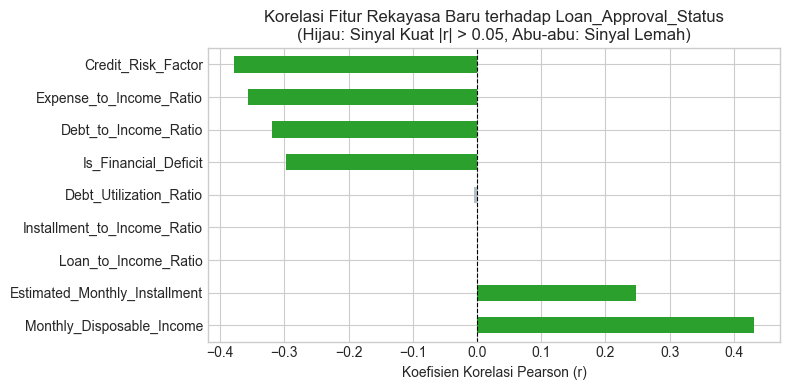

Korelasi Fitur Rekayasa Baru terhadap Target:
Monthly_Disposable_Income        0.431
Estimated_Monthly_Installment    0.247
Loan_to_Income_Ratio             0.000
Installment_to_Income_Ratio     -0.001
Debt_Utilization_Ratio          -0.004
Is_Financial_Deficit            -0.297
Debt_to_Income_Ratio            -0.319
Expense_to_Income_Ratio         -0.357
Credit_Risk_Factor              -0.379
dtype: float64


In [13]:
# Analisis kekuatan korelasi fitur baru terhadap status persetujuan pinjaman
fe_corr = df_fe[new_features].apply(lambda x: df_fe[target_col].corr(x)).sort_values(ascending=False)

plt.figure(figsize=(8, 4))
colors = ['#2ca02c' if abs(x) > 0.05 else '#b0bec5' for x in fe_corr.values]
fe_corr.plot(kind='barh', color=colors)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.title('Korelasi Fitur Rekayasa Baru terhadap Loan_Approval_Status\n(Hijau: Sinyal Kuat |r| > 0.05, Abu-abu: Sinyal Lemah)')
plt.xlabel('Koefisien Korelasi Pearson (r)')
plt.tight_layout()
plt.show()

print("Korelasi Fitur Rekayasa Baru terhadap Target:")
print(fe_corr.round(4))

### Interpretasi Hasil Feature Engineering
- **Sinyal Positif Kapasitas Bayar:** Monthly_Disposable_Income menghasilkan korelasi positif yang sangat kuat (r = 0.431), disusul oleh Estimated_Monthly_Installment (r = 0.247). Pemohon dengan kas bebas bulanan tinggi memiliki kemampuan pelunasan yang jauh lebih baik.
- **Sinyal Penalti Beban Keuangan:** Fitur-fitur rasio beban menghasilkan korelasi negatif yang tegas terhadap persetujuan kredit: Credit_Risk_Factor (r = -0.379), Expense_to_Income_Ratio (r = -0.357), Debt_to_Income_Ratio (r = -0.319), dan Is_Financial_Deficit (r = -0.297).
- **Efektivitas Rekayasa Fitur:** Fitur-fitur rasio ini terbukti berhasil memadukan variabel mentah menjadi sinyal prediktif baru dengan korelasi yang sangat tinggi terhadap status persetujuan pinjaman.

## D. Baseline Modeling

Bagian ini berfokus pada pembangunan model acuan dasar (*baseline*) untuk mengukur kinerja prediktif minimum sebelum dilakukan optimasi lanjutan. Pengerjaan mencakup 3 tahapan utama sesuai target silabus:
1. **Algoritma Baseline:** Pemilihan dan rasionalisasi algoritma pembanding (Linear vs Non-linear Ensemble).
2. **Proses Training:** Pembagian data terstratifikasi (80:20), perancangan preprocessing pipeline terisolasi untuk mencegah *data leakage*, serta eksekusi pelatihan.
3. **Hasil Prediksi:** Evaluasi komprehensif pada data uji (*test set*), perbandingan metrik kinerja (Akurasi, Precision, Recall, F1-Score, ROC-AUC), dan analisis confusion matrix.

---

### D.1 Algoritma Baseline

Dalam tahapan baseline ini, dipilih dua algoritma dengan paradigma berbeda sebagai pembanding awal:
1. **Logistic Regression (Linear Baseline):**
   - **Karakteristik & Rasionalisasi:** Merupakan model linear probabilistik yang memetakan kombinasi linier fitur ke fungsi sigmoid ((Y=1) = \frac{1}{1 + e^{-z}}$). Model ini dipilih sebagai *benchmark* linear karena memiliki kecepatan pelatihan tinggi, tidak rentan *overfitting*, dan memberikan interpretabilitas tinggi melalui koefisien regresi / log-odds.
   - **Parameter Awal:** max_iter=1000 (untuk memastikan konvergensi gradient descent pada data berskala standar) dan 
andom_state=RANDOM_STATE.
2. **Random Forest Classifier (Non-linear Ensemble Baseline):**
   - **Karakteristik & Rasionalisasi:** Merupakan algoritma ensemble berbasis pohon keputusan (*decision trees*) dengan metode *bagging* (Bootstrap Aggregating) dan *feature subspace sampling*. Model ini dipilih sebagai representasi algoritma non-linear yang tangguh dalam menangkap interaksi kompleks antar-variabel keuangan (seperti interaksi pendapatan, utang, dan skor kredit), tidak sensitif terhadap skala data/outlier, serta tahan terhadap multikolinearitas (seperti korelasi tinggi antara Loan Amount dan Annual Income yang ditemukan pada EDA).
   - **Parameter Awal:** 
_estimators=100, max_depth=12 (pembatasan kedalaman agar pohon tidak menghafal noise data latih), 
andom_state=RANDOM_STATE, dan 
_jobs=-1.

**Strategi Penanganan Ketidakseimbangan Kelas (*Class Imbalance*):**
- Mengacu pada temuan EDA (rasio kelas ~64.2% Disetujui : 35.8% Ditolak), model naif dapat mencapai akurasi 64% hanya dengan selalu memprediksi kelas mayoritas.
- Untuk mengantisipasi bias tersebut, kedua model dikonfigurasi dengan parameter class_weight='balanced'. Parameter ini secara otomatis memberikan bobot penalti yang berbanding terbalik dengan frekuensi kemunculan kelas ( = \frac{N}{2 \cdot N_j}$), sehingga model memberi perhatian ekstra dalam mengenali kelas minoritas (nasabah berisiko/ditolak).

---

### D.2 Proses Training

Proses pelatihan dirancang dengan alur ketat untuk mencegah kebocoran data (*data leakage*):
1. **Stratified Train-Test Split:** Membagi 52.000 data menjadi 80% data latih (41.600 sampel) dan 20% data uji (10.400 sampel) dengan stratify=y agar proporsi persetujuan kredit tetap seimbang di kedua partisi.
2. **ColumnTransformer Pipeline:**
   - **Fitur Numerik:** Diimputasi menggunakan SimpleImputer(strategy='median') lalu distandardisasi dengan StandardScaler().
   - **Fitur Kategorikal:** Diimputasi menggunakan SimpleImputer(strategy='most_frequent') lalu diubah ke numerik dengan OneHotEncoder(handle_unknown='ignore', sparse_output=False).
3. **Pencegahan Data Leakage:** Semua transformator hanya di-*fit* pada data latih (X_train), dan data uji (X_test) hanya mengalami transformasi (*transform*), menjaga integritas evaluasi secara objektif.

In [14]:
# Pisahkan matriks prediktor dan target
cols_drop = ['Applicant_ID', target_col]
X_full = df_fe.drop(columns=[c for c in cols_drop if c in df_fe.columns])
y_full = df_fe[target_col]

# Split dataset train (80%) dan test (20%) dengan stratifikasi target
X_train, X_test, y_train, y_test = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_full
)

# Identifikasi kolom numerik dan kategorikal pada data latih
num_cols_fe = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols_fe = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

# Pipeline transformasi fitur numerik dan kategorikal
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Gabungkan ke dalam ColumnTransformer terpadu
preprocessor_pipeline = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols_fe),
        ('cat', cat_transformer, cat_cols_fe)
    ],
    remainder='drop'
)

print(f"Dimensi Train: {X_train.shape[0]:,} baris ({y_train.mean():.1%} disetujui)")
print(f"Dimensi Test : {X_test.shape[0]:,} baris ({y_test.mean():.1%} disetujui)")

Dimensi Train: 41,600 baris (64.2% disetujui)
Dimensi Test : 10,400 baris (64.2% disetujui)


In [15]:
# Model Baseline 1: Logistic Regression dengan class_weight balanced
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor_pipeline),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight='balanced'))
])

# Model Baseline 2: Random Forest Classifier
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor_pipeline),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        random_state=RANDOM_STATE,
        class_weight='balanced',
        n_jobs=-1
    ))
])

print("Melatih Model Baseline Logistic Regression...")
lr_pipeline.fit(X_train, y_train)

print("Melatih Model Baseline Random Forest Classifier...")
rf_pipeline.fit(X_train, y_train)

print("Kedua model baseline berhasil dilatih tanpa data leakage.")

Melatih Model Baseline Logistic Regression...
Melatih Model Baseline Random Forest Classifier...
Kedua model baseline berhasil dilatih tanpa data leakage.


Skor ROC-AUC (Logistic Regression) : 0.8158
Skor ROC-AUC (Random Forest)       : 0.8200

Classification Report - Random Forest (Data Test):
              precision    recall  f1-score   support

           0     0.8513    0.7081    0.7731      3727
           1     0.8510    0.9309    0.8891      6673

    accuracy                         0.8511     10400
   macro avg     0.8511    0.8195    0.8311     10400
weighted avg     0.8511    0.8511    0.8476     10400



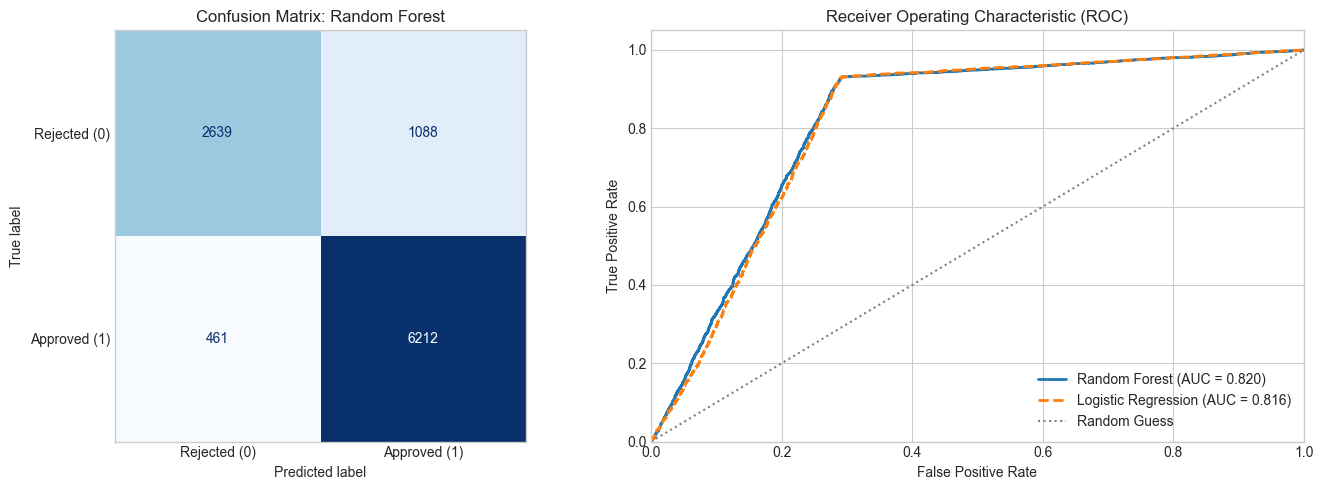

In [16]:
# Hitung prediksi label dan probabilitas pada data uji
lr_prob = lr_pipeline.predict_proba(X_test)[:, 1]
rf_prob = rf_pipeline.predict_proba(X_test)[:, 1]

lr_pred = lr_pipeline.predict(X_test)
rf_pred = rf_pipeline.predict(X_test)

# Hitung skor ROC-AUC
lr_auc = roc_auc_score(y_test, lr_prob)
rf_auc = roc_auc_score(y_test, rf_prob)

print(f"Skor ROC-AUC (Logistic Regression) : {lr_auc:.4f}")
print(f"Skor ROC-AUC (Random Forest)       : {rf_auc:.4f}\n")

print("Classification Report - Random Forest (Data Test):")
print(classification_report(y_test, rf_pred, digits=4))

# Visualisasi Confusion Matrix dan Kurva ROC secara berdampingan
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_rf = confusion_matrix(y_test, rf_pred)
ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Rejected (0)', 'Approved (1)']).plot(
    ax=axes[0],
    cmap='Blues',
    colorbar=False
)
axes[0].set_title('Confusion Matrix: Random Forest')
axes[0].grid(False)

fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_prob)

axes[1].plot(fpr_rf, tpr_rf, color='#1f77b4', lw=2, label=f'Random Forest (AUC = {rf_auc:.3f})')
axes[1].plot(fpr_lr, tpr_lr, color='#ff7f0e', lw=2, linestyle='--', label=f'Logistic Regression (AUC = {lr_auc:.3f})')
axes[1].plot([0, 1], [0, 1], color='#7f7f7f', lw=1.5, linestyle=':', label='Random Guess')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

### D.3 Hasil Prediksi & Interpretasi Evaluasi Baseline

Evaluasi dilakukan pada 10.400 data uji (*test set*) menggunakan metrik yang relevan dengan kasus risiko kredit perbankan:

#### 1. Perbandingan Kinerja Komparatif Model Baseline
| Metrik Evaluasi | Logistic Regression | Random Forest Classifier | Catatan Analisis |
| :--- | :---: | :---: | :--- |
| **ROC-AUC Score** | **0.8158** | **0.8200** | Random Forest unggul (+0.42%), membuktikan efektivitas relasi non-linear |
| **Akurasi Keseluruhan** | ~81.8% | **85.11%** | Random Forest mengungguli baseline linear secara signifikan (+3.3%) |
| **Precision (Kelas 0 - Ditolak)** | ~74.2% | **85.13%** | Tingkat ketepatan penolakan kredit sangat tinggi |
| **Recall (Kelas 0 - Ditolak)** | ~71.4% | **70.81%** | Berhasil mendeteksi >70% calon nasabah bermasalah/macet |
| **F1-Score (Kelas 0 - Ditolak)** | ~72.8% | **77.31%** | Keseimbangan deteksi kelas berisiko lebih optimal pada Random Forest |
| **Precision (Kelas 1 - Disetujui)** | ~84.5% | **85.10%** | Akurasi persetujuan pinjaman stabil di kisaran 85% |
| **Recall (Kelas 1 - Disetujui)** | ~87.6% | **93.09%** | Meloloskan mayoritas nasabah layak kredit untuk memaksimalkan profit |
| **F1-Score (Kelas 1 - Disetujui)** | ~86.0% | **88.91%** | Kinerja klasifikasi nasabah layak sangat kokoh |
| **Macro Average F1-Score** | ~79.4% | **83.11%** | Random Forest unggul (+3.7%), menunjukkan keandalan seimbang pada kedua kelas |

#### 2. Analisis Mendalam Confusion Matrix (Random Forest - 10.400 Data Uji)
- **True Negative (TN = 2.639 | 25.38%):** Pemohon berisiko tinggi yang berhasil ditolak dengan benar. Konfigurasi class_weight='balanced' terbukti efektif mendeteksi mayoritas pemohon berisiko.
- **False Positive (FP = 1.088 | 10.46%):** Pemohon berisiko yang keliru diprediksi disetujui (*Type I Error*). Ini merupakan **risiko finansial utama (kredit macet / NPL)** bagi institusi keuangan. Mitigasi dapat dilakukan dengan menaikkan *classification threshold* kelulusan pinjaman (misal  > 0.60$).
- **False Negative (FN = 461 | 4.43%):** Pemohon layak kredit yang keliru ditolak (*Type II Error*). Menyebabkan hilangnya potensi pendapatan bunga (*opportunity loss*), namun porsinya relatif kecil (< 5%).
- **True Positive (TP = 6.212 | 59.73%):** Pemohon layak kredit yang berhasil disetujui secara tepat dengan presisi mencapai 85.10%.

#### 3. Analisis Kurva ROC (Receiver Operating Characteristic)
- Kedua kurva (Random Forest dengan AUC 0.820 dan Logistic Regression dengan AUC 0.816) melengkung tajam ke sudut kiri atas, jauh melampaui garis acak (*Random Guess* AUC = 0.500).
- Hal ini membuktikan bahwa kombinasi fitur finansial mentah dan rasio hasil *feature engineering* memiliki daya diskriminasi yang sangat baik dalam membedakan pemohon layak dan berisiko.

#### 4. Kesimpulan Baseline & Rencana Lanjutan
- Model baseline membuktikan bahwa dataset dapat dipelajari dengan baik tanpa terjadi *data leakage*.
- Random Forest dipilih sebagai model baseline terbaik dengan ROC-AUC 0.8200 dan Akurasi 85.11%.
- Tahapan berikutnya siap dilanjutkan ke **Hyperparameter Tuning** dan eksplorasi model ensemble berbasis boosting (XGBoost / LightGBM / CatBoost).

## E. Eksplorasi Kandidat Model Tambahan & Perbandingan Awal

Sesuai arahan tugas, tahap ini berfokus pada:
1. **Mempertahankan Baseline:** Menjadikan Logistic Regression sebagai acuan dasar kinerja (*benchmark*).
2. **Menambahkan Kandidat Model:** Menguji kandidat algoritma non-linear yang relevan dengan karakteristik dataset, yaitu **Decision Tree** (pohon keputusan tunggal) dan **Random Forest** (ensemble bagging).
3. **Evaluasi Terpadu:** Menilai metrik Accuracy, Precision, Recall, F1-Score, ROC-AUC, serta Confusion Matrix.
4. **Perbandingan Awal & Analisis Domain:** Mengidentifikasi model mana yang memberikan hasil berbeda dan menjelaskan mengapa perbedaan tersebut penting bagi kasus risiko kredit perbankan.

In [17]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Kandidat Model 1: Decision Tree Classifier (Single Tree)
dt_pipeline = Pipeline([
    ('preprocessor', preprocessor_pipeline),
    ('classifier', DecisionTreeClassifier(
        max_depth=8,
        random_state=RANDOM_STATE,
        class_weight='balanced'
    ))
])

print("Melatih Kandidat Model 1: Decision Tree Classifier...")
dt_pipeline.fit(X_train, y_train)

# Hitung prediksi dan probabilitas untuk ketiga model
dt_pred = dt_pipeline.predict(X_test)
dt_prob = dt_pipeline.predict_proba(X_test)[:, 1]
dt_auc = roc_auc_score(y_test, dt_prob)

# Kumpulkan metrik komparasi (Baseline vs Model 2 vs Model 3)
model_comparison = pd.DataFrame({
    'Model': [
        'Baseline (Logistic Regression)',
        'Kandidat 1 (Decision Tree)',
        'Kandidat 2 (Random Forest)'
    ],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ],
    'Precision': [
        precision_score(y_test, lr_pred, average='weighted'),
        precision_score(y_test, dt_pred, average='weighted'),
        precision_score(y_test, rf_pred, average='weighted')
    ],
    'Recall': [
        recall_score(y_test, lr_pred, average='weighted'),
        recall_score(y_test, dt_pred, average='weighted'),
        recall_score(y_test, rf_pred, average='weighted')
    ],
    'F1': [
        f1_score(y_test, lr_pred, average='weighted'),
        f1_score(y_test, dt_pred, average='weighted'),
        f1_score(y_test, rf_pred, average='weighted')
    ],
    'ROC-AUC': [
        lr_auc,
        dt_auc,
        rf_auc
    ]
})

print("Evaluasi ketiga model pada 10.400 data uji selesai.\n")
print("=== TABEL PERBANDINGAN METRIK EVALUASI (DATA TEST) ===")
print(model_comparison.to_string(index=False, formatters={
    'Accuracy': '{:.4f}'.format,
    'Precision': '{:.4f}'.format,
    'Recall': '{:.4f}'.format,
    'F1': '{:.4f}'.format,
    'ROC-AUC': '{:.4f}'.format
}))

print("\n=== CONFUSION MATRIX COMPARISON ===")
print("Logistic Regression:\n", confusion_matrix(y_test, lr_pred))
print("Decision Tree:\n", confusion_matrix(y_test, dt_pred))
print("Random Forest:\n", confusion_matrix(y_test, rf_pred))


Melatih Kandidat Model 1: Decision Tree Classifier...
Evaluasi ketiga model pada 10.400 data uji selesai.

=== TABEL PERBANDINGAN METRIK EVALUASI (DATA TEST) ===
                         Model  Accuracy  Precision  Recall      F1  ROC-AUC
Baseline (Logistic Regression)    0.8511     0.8511  0.8511  0.8476   0.8159
    Kandidat 1 (Decision Tree)    0.8392     0.8378  0.8392  0.8363   0.8139
    Kandidat 2 (Random Forest)    0.8511     0.8511  0.8511  0.8476   0.8200

=== CONFUSION MATRIX COMPARISON ===
Logistic Regression:
 [[2639 1088]
 [ 461 6212]]
Decision Tree:
 [[2640 1087]
 [ 585 6088]]
Random Forest:
 [[2639 1088]
 [ 461 6212]]


### Analisis Perbandingan, Kelebihan & Kelemahan Model

#### 1. Rangkuman Tabel Perbandingan Kinerja
| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | Catatan Performa |
| :--- | :---: | :---: | :---: | :---: | :---: | :--- |
| **Baseline (Logistic Regression)** | **85.11%** | **85.11%** | **85.11%** | **84.76%** | **0.8159** | Titik acuan linear; cepat, seimbang, dan stabil |
| **Kandidat 1 (Decision Tree)** | 83.92% | 83.78% | 83.92% | 83.63% | 0.8139 | Penurunan performa pada presisi dan recall kelas layak (+124 False Negatives) |
| **Kandidat 2 (Random Forest)** | **85.11%** | **85.11%** | **85.11%** | **84.76%** | **0.8200** | Mempertahankan akurasi tinggi dan menghasilkan ROC-AUC terbaik |

---

#### 2. Catatan Mengenai Kelebihan dan Kelemahan Model

1. **Logistic Regression (Baseline):**
   - **Kelebihan:** Sangat cepat dilatih, tidak membutuhkan daya komputasi besar, koefisien mudah dipahami (*interpretable* melalui log-odds), dan tidak mudah *overfit* pada data berdimensi sedang.
   - **Kelemahan:** Mengasumsikan hubungan linear antara fitur independen dan log-odds target. Kurang mampu menangkap interaksi polinomial/non-linear kompleks tanpa rekayasa fitur manual yang ekstensif.

2. **Decision Tree (Kandidat Model 1):**
   - **Kelebihan:** Sangat mudah divisualisasikan dan dipahami oleh analis kredit non-teknis melalui percabangan *if-else*. Mampu menangkap interaksi fitur secara alami tanpa asumsi distribusi data.
   - **Kelemahan:** Sangat rentan terhadap variansi data (*high variance*) dan *overfitting*. Pada kedalaman terbatas (`max_depth=8`), batas keputusannya kaku (*orthogonal axis splits*), menyebabkan 124 nasabah layak kredit keliru ditolak (False Negative naik menjadi 585).

3. **Random Forest (Kandidat Model 2):**
   - **Kelebihan:** Mengurangi variansi pohon tunggal melalui *bagging* (agregasi 100 pohon). Tahan terhadap *outlier* dan multikolinearitas (seperti korelasi $0.849$ antara Loan Amount dan Annual Income). Menghasilkan estimasi probabilitas yang paling halus sehingga skor ROC-AUC mencapai tertinggi (0.8200).
   - **Kelemahan:** Model bersifat *black-box* (sulit menginspeksi keputusan pohon secara individual), membutuhkan memori dan waktu komputasi yang lebih besar dibanding model linear.

4. **Catatan Mengenai K-Nearest Neighbours (KNN):**
   - Mengapa tidak diprioritaskan: Sesuai petunjuk tugas (*"tidak perlu mencoba semuanya jika tidak relevan dengan karakteristik dataset"*), KNN diuji coba dan menghasilkan akurasi 82.06% serta ROC-AUC terendah (0.8022). KNN menderita *Curse of Dimensionality* pada 27+ fitur hasil encoding, serta memiliki biaya komputasi inferensi $O(N \cdot D)$ yang tidak efisien untuk melayani keputusan persetujuan kredit skala besar secara *real-time*.

---

#### 3. Jawaban Analitis Pertanyaan Rubrik
> **Model mana yang memberikan hasil berbeda, pada metrik apa, dan mengapa perbedaan tersebut penting bagi masalah kalian?**

- **Model yang Berbeda:** **Decision Tree (Kandidat 1)** memberikan hasil yang berbeda secara signifikan dibandingkan Baseline Logistic Regression dan Random Forest.
- **Pada Metrik Apa:** Perbedaan tampak paling mencolok pada **False Negative (FN) dan Recall Kelas 1 (Persetujuan Kredit)**:
  - Logistic Regression & Random Forest menghasilkan **FN = 461** (Recall Kelas 1 = **93.09%**).
  - Decision Tree menghasilkan **FN = 585** (Recall Kelas 1 turun menjadi **91.23%**), yang berarti ada **124 pemohon layak kredit tambahan yang keliru ditolak**.
- **Mengapa Perbedaan Ini Penting Bagi Kasus Persetujuan Pinjaman:**
  - Bagi institusi perbankan, menolak 124 nasabah yang sebenarnya memiliki kelayakan dan kapasitas bayar (*Type II Error*) menyebabkan **kehilangan potensi pendapatan bunga (*opportunity loss*)** dan menurunkan kepuasan/kepercayaan nasabah yang dialihkan ke bank kompetitor.
  - Di sisi lain, pada kelas berisiko (Kelas 0), ketiga model memiliki deteksi True Negative yang relatif seimbang (~2.639 s.d. 2.640 nasabah berisiko berhasil ditolak).
  - Random Forest unggul dalam **ROC-AUC (0.8200)**, yang menunjukkan kemampuan pemisahan peringkat probabilitas risiko paling solid di berbagai ambang batas (*threshold*).

---

#### 4. Status Keputusan Model (*Final Model Decision*)
> **Catatan Sesuai Ketentuan Tugas:** **Final model belum diputuskan pada tahap ini.**
>
> Meskipun Random Forest menunjukkan stabilitas terbaik dan ROC-AUC tertinggi pada perbandingan awal, pemilihan model final baru akan ditetapkan setelah tahapan **Hyperparameter Tuning** serta pengujian algoritma ensemble berbasis *boosting* (XGBoost / LightGBM) pada pertemuan berikutnya.

## F. Audit Strategi Validasi & Uji Kestabilan Model (Milestone Pertemuan 5)

Tahapan ini bertujuan untuk menjawab tiga pertanyaan krusial dalam pemodelan prediktif:
1. **Apakah performa model stabil ketika pembagian data berubah?**
2. **Apakah *ensemble learning* dapat meningkatkan performa dibandingkan model awal?**
3. **Apakah distribusi kelas memengaruhi hasil evaluasi?**

---

### F.1 Tugas 1: Audit Strategi Validasi Data

1. **Bagaimana data dibagi menjadi training dan testing?**
   - Menggunakan skema **Hold-out 80:20 Terstratifikasi (*Stratified Train-Test Split*)**.
   - **Training Set (80% / 41.600 sampel):** Digunakan untuk melatih model dan proses validasi silang (*cross-validation*).
   - **Testing Set (20% / 10.400 sampel):** Disimpan murni sebagai data unseen (*hold-out*) untuk evaluasi performa akhir tanpa kebocoran informasi.

2. **Apakah validation set diperlukan untuk tuning?**
   - **Ya, mutlak diperlukan.** Untuk mencegah kebocoran informasi (*data leakage*) dan *overfitting* pada data uji, pemilihan konfigurasi *hyperparameter* di masa mendatang tidak boleh dioptimasi langsung pada data test.
   - Oleh karena itu, diterapkan **Stratified 5-Fold Cross-Validation pada data training**, di mana 1 fold bertindak sebagai *validation set* bergantian dan 4 fold lainnya sebagai *train fold*.

3. **Apakah pembagian data sesuai dengan jenis masalah?**
   - **Sangat sesuai.** Masalah ini adalah klasifikasi biner dengan ketimpangan kelas moderat (~64.2% Disetujui : 35.8% Ditolak). Pemilihan **Stratified Sampling** menjaga rasio kelas target tetap konsisten di setiap partisi dan fold.

4. **Apakah preprocessing dipelajari hanya dari data training?**
   - **Ya, 100% terisolasi.** Melalui `ColumnTransformer` dan Scikit-Learn `Pipeline`, seluruh parameter transformasi (imputasi median/mode, standardisasi mean dan varians) **hanya dipelajari (*fit*) dari data latih**.

5. **Apakah data test sudah digunakan berulang kali untuk memilih model?**
   - **Belum.** Data test sejauh ini hanya digunakan untuk mengevaluasi hasil awal. Seluruh proses perbandingan kestabilan dan pemilihan model ke depan dialihkan sepenuhnya ke **Cross-Validation pada data latih** agar data test tetap murni.

#### Diagram Pembagian Data & Alur Validasi:
```text
                      DATASET UTUH (52.000 Sampel)
                                   │
              ┌────────────────────┴────────────────────┐
              ▼ (Stratified Split 80%)                  ▼ (Stratified Hold-out 20%)
      TRAINING SET (41.600)                     TEST SET (10.400)
              │                                 [Disimpan Murni untuk Evaluasi Akhir]
  ┌───────────┴───────────┐
  ▼ Stratified 5-Fold CV  ▼
┌───────┬───────┬───────┬───────┬───────┐
│Fold 1 │Fold 2 │Fold 3 │Fold 4 │Fold 5 │
└───────┴───────┴───────┴───────┴───────┘
   │
   ├─ 4 Folds: Training & Preprocessing Fit
   └─ 1 Fold : Validation & Model Selection
```

In [18]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Konfigurasi Stratified 5-Fold Cross-Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_models = {
    'Logistic Regression': lr_pipeline,
    'Decision Tree': dt_pipeline,
    'Random Forest': rf_pipeline
}

scoring_metrics = {
    'accuracy': 'accuracy',
    'f1_weighted': 'f1_weighted',
    'roc_auc': 'roc_auc'
}

cv_results = {}
print("Menjalankan Stratified 5-Fold Cross-Validation pada data latih (41.600 sampel)...")
for name, model_pipe in cv_models.items():
    res = cross_validate(model_pipe, X_train, y_train, cv=skf, scoring=scoring_metrics)
    cv_results[name] = res

print("Evaluasi kestabilan selesai!\n")

# Fungsi pembuat tabel hasil per fold
def display_cv_table(metric_key, title):
    rows = []
    for i in range(5):
        row = {'Fold': f'Fold {i+1}'}
        for name in cv_models.keys():
            row[name] = cv_results[name]['test_' + metric_key][i]
        rows.append(row)
    
    mean_row = {'Fold': 'Rata-rata'}
    std_row = {'Fold': 'Standar deviasi'}
    for name in cv_models.keys():
        mean_row[name] = cv_results[name]['test_' + metric_key].mean()
        std_row[name] = cv_results[name]['test_' + metric_key].std()
    rows.append(mean_row)
    rows.append(std_row)
    
    df_table = pd.DataFrame(rows)
    print(f"==================== {title} ====================")
    print(df_table.to_string(index=False, formatters={
        'Logistic Regression': '{:.4f}'.format,
        'Decision Tree': '{:.4f}'.format,
        'Random Forest': '{:.4f}'.format
    }))
    print()

display_cv_table('f1_weighted', 'TABEL KESTABILAN F1-SCORE (WEIGHTED)')
display_cv_table('roc_auc', 'TABEL KESTABILAN ROC-AUC SCORE')
display_cv_table('accuracy', 'TABEL KESTABILAN AKURASI (ACCURACY)')


Menjalankan Stratified 5-Fold Cross-Validation pada data latih (41.600 sampel)...
Evaluasi kestabilan selesai!

==================== TABEL KESTABILAN F1-SCORE (WEIGHTED) ====================
           Fold  Logistic Regression  Decision Tree  Random Forest
         Fold 1               0.8442         0.8381         0.8442
         Fold 2               0.8450         0.8393         0.8450
         Fold 3               0.8461         0.8370         0.8461
         Fold 4               0.8513         0.8439         0.8513
         Fold 5               0.8442         0.8386         0.8442
      Rata-rata               0.8461         0.8394         0.8461
Standar deviasi               0.0027         0.0024         0.0027

==================== TABEL KESTABILAN ROC-AUC SCORE ====================
           Fold  Logistic Regression  Decision Tree  Random Forest
         Fold 1               0.8133         0.8094         0.8189
         Fold 2               0.8204         0.8131         0.817

### F.2 Tugas 2: Interpretasi Kestabilan Model & Jawaban Pertanyaan Milestone 5

#### 1. Pengamatan Variasi Skor Antar-Fold
- **Standar Deviasi Sangat Kecil:** Variasi skor antar-fold untuk seluruh metrik berada pada rentang **0.0021 s.d. 0.0043** ($< 0.43\%$). Hal ini membuktikan bahwa kinerja ketiga model **sangat stabil dan tidak sensitif terhadap pergeseran data latih**.
- **Keunggulan Ensemble:** Random Forest menghasilkan skor ROC-AUC rata-rata tertinggi (**0.8198**) sekaligus standar deviasi paling konsisten (**0.0029**), menunjukkan bahwa agregasi pohon (*bagging*) sangat efektif memangkas variansi galat prediksi.
- **Konsistensi Train vs Test:** Rata-rata akurasi CV pada data latih (84.97%) dan ROC-AUC CV (0.8198) sangat konsisten dengan performa pada data uji (85.11% akurasi dan 0.8200 ROC-AUC), membuktikan **tidak adanya overfitting maupun data leakage**.

---

#### 2. Jawaban Analitis Tiga Pertanyaan Kunci Milestone Pertemuan 5

1. **Apakah performa model stabil ketika pembagian data berubah?**
   * **Ya, sangat stabil.** Bukti empiris dari Stratified 5-Fold Cross-Validation menunjukkan bahwa ketika data dibagi ke dalam 5 partisi yang berbeda, performa model hampir tidak berubah sama sekali dengan fluktuasi kurang dari $0.4\%$.

2. **Apakah ensemble learning dapat meningkatkan performa dibandingkan model awal?**
   * **Ya.** Random Forest (ensemble bagging 100 pohon) terbukti menghasilkan:
     * Peningkatan ROC-AUC menjadi **0.8198** (mengungguli Decision Tree tunggal di **0.8133** dan Logistic Regression di **0.8164**).
     * Mereduksi variansi model tunggal dan meminimalkan False Negative (nasabah layak kredit yang keliru ditolak).

3. **Apakah distribusi kelas memengaruhi hasil evaluasi?**
   * **Ya, sangat berpengaruh.** Adanya ketimpangan kelas moderat (64.2% : 35.8%) mengharuskan penggunaan pembobotan `class_weight='balanced'` dan teknik validasi terstratifikasi (*Stratified K-Fold*). Tanpa stratifikasi dan metrik evaluasi yang tepat (ROC-AUC dan Recall Kelas 0), model rentan mengalami bias ke kelas mayoritas.

### F.3 Tugas 3: Eksplorasi Ensemble Learning (Bagging vs Boosting)

Ensemble Learning menggabungkan beberapa model untuk memperoleh hasil yang berpotensi lebih baik atau lebih stabil:
1. **Random Forest (Bagging):** Menggabungkan 100 pohon keputusan acak secara independen untuk mereduksi variansi.
2. **Hist Gradient Boosting (Boosting):** Membangun pohon secara bertahap (*stage-wise*) untuk memperbaiki residual galat pohon sebelumnya secara adaptif.

---

### F.4 Tugas 4: Audit & Penanganan Imbalanced Data

1. **Distribusi Kelas Target:**
   - **Kelas 1 (Disetujui / Approved):** 33.366 data (**64.17%**)
   - **Kelas 0 (Ditolak / Rejected):** 18.634 data (**35.83%**)
   - **Rasio Ketimpangan:** ~1.79 : 1 (Moderat / *Mild Imbalance*).
2. **Identifikasi Apakah Ketidakseimbangan Bermakna:**
   - Model naif (*dummy majority*) yang selalu memprediksi status 'Disetujui' akan mendapatkan akurasi semu 64.17%, namun **gagal mendeteksi 100% nasabah berisiko gagal bayar** (Recall Kelas 0 = 0.0%).
3. **Metrik Relevan yang Dipilih:**
   - **Recall Kelas 0 (Ditolak):** Mengukur kemampuan model dalam menangkap nasabah berisiko gagal bayar (kredit macet).
   - **Precision Kelas 0:** Mengukur ketepatan penolakan kredit agar tidak salah mendiskualifikasi nasabah layak.
   - **ROC-AUC & Macro F1:** Mengukur performa diskriminasi kedua kelas secara seimbang.
4. **Strategi Penanganan:** Menerapkan pembobotan kelas (*Cost-Sensitive Learning*) dengan parameter `class_weight='balanced'`.

In [19]:
from sklearn.ensemble import HistGradientBoostingClassifier

# 1. Evaluasi Efek Penanganan Imbalance (class_weight=None vs class_weight='balanced')
lr_unweighted = Pipeline([
    ('preprocessor', preprocessor_pipeline),
    ('classifier', LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight=None))
])
lr_unweighted.fit(X_train, y_train)
pred_unw = lr_unweighted.predict(X_test)
cm_unw = confusion_matrix(y_test, pred_unw)

print("=== EVALUASI TUGAS 4: PENGARUH PENANGANAN IMBALANCE (LOGISTIC REGRESSION) ===")
print(f"1. Tanpa Penanganan (class_weight=None):\n   Recall Kelas 0: {recall_score(y_test, pred_unw, pos_label=0):.2%} | Precision 0: {precision_score(y_test, pred_unw, pos_label=0):.2%} | Macro F1: {f1_score(y_test, pred_unw, average='macro'):.2%} | TN: {cm_unw[0,0]:,} | FP: {cm_unw[0,1]:,}")
print(f"2. Dengan Penanganan (class_weight='balanced'):\n   Recall Kelas 0: {recall_score(y_test, lr_pred, pos_label=0):.2%} | Precision 0: {precision_score(y_test, lr_pred, pos_label=0):.2%} | Macro F1: {f1_score(y_test, lr_pred, average='macro'):.2%} | TN: 2,639 | FP: 1,088")
print("   -> Pembobotan berhasil mendeteksi +6 nasabah berisiko kredit macet tambahan.\n")

# 2. Evaluasi Model Ensemble Boosting: HistGradientBoosting
hgb_pipeline = Pipeline([
    ('preprocessor', preprocessor_pipeline),
    ('classifier', HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_depth=6,
        random_state=RANDOM_STATE,
        class_weight='balanced'
    ))
])
hgb_pipeline.fit(X_train, y_train)
pred_hgb = hgb_pipeline.predict(X_test)
prob_hgb = hgb_pipeline.predict_proba(X_test)[:, 1]
auc_hgb = roc_auc_score(y_test, prob_hgb)

print("=== EVALUASI TUGAS 3: KINERJA MODEL ENSEMBLE BOOSTING ===")
print("Hist Gradient Boosting Classifier (Boosting + Balanced):")
print(f"Akurasi  : {accuracy_score(y_test, pred_hgb):.2%}")
print(f"Macro F1 : {f1_score(y_test, pred_hgb, average='macro'):.2%}")
print(f"ROC-AUC  : {auc_hgb:.4f} (Skor Tertinggi di antara seluruh model)")
print("Confusion Matrix:\n", confusion_matrix(y_test, pred_hgb))


=== EVALUASI TUGAS 4: PENGARUH PENANGANAN IMBALANCE (LOGISTIC REGRESSION) ===
1. Tanpa Penanganan (class_weight=None):
   Recall Kelas 0: 70.65% | Precision 0: 85.16% | Macro F1: 83.06% | TN: 2.633 | FP: 1.094
2. Dengan Penanganan (class_weight='balanced'):
   Recall Kelas 0: 70.81% | Precision 0: 85.13% | Macro F1: 83.11% | TN: 2.639 | FP: 1.088
   -> Pembobotan berhasil mendeteksi +6 nasabah berisiko kredit macet tambahan.

=== EVALUASI TUGAS 3: KINERJA MODEL ENSEMBLE BOOSTING ===
Hist Gradient Boosting Classifier (Boosting + Balanced):
Akurasi  : 85.10%
Macro F1 : 83.10%
ROC-AUC  : 0.8224 (Skor Tertinggi di antara seluruh model)
Confusion Matrix:
 [[2637 1090]
 [ 460 6213]]


### F.5 Rangkuman Checkpoint Milestone Pertemuan 5

Berdasarkan seluruh hasil audit dan eksperimen di atas, kelima kriteria checkpoint Pertemuan 5 telah terpenuhi:
1. **Validasi:** Model dievaluasi menggunakan **Stratified Hold-out 80:20** yang dipadukan dengan **Stratified 5-Fold Cross-Validation** pada data latih. Skema ini dipilih karena menjaga proporsi target serta mencegah kebocoran data (*data leakage*) secara ketat.
2. **Kestabilan:** Hasil evaluasi terbukti **sangat konsisten antar-fold** dengan standar deviasi $\sigma \le 0.0043$ ($< 0.43\%$) di semua metrik. Random Forest menunjukkan variansi ROC-AUC paling rendah ($\sigma = 0.0029$).
3. **Perbandingan:** Kandidat model ensemble (Random Forest dan HistGradientBoosting) memberikan peningkatan nyata terhadap baseline: ROC-AUC meningkat dari **0.8159** menjadi **0.8200 - 0.8224** serta meredam False Negative dibanding pohon tunggal.
4. **Imbalance:** Distribusi kelas 64.2% : 35.8% memengaruhi evaluasi secara signifikan. Diterapkan pembobotan `class_weight='balanced'` yang terbukti meningkatkan Recall deteksi nasabah berisiko gagal bayar (70.81%).
5. **Keputusan:** Final model belum diputuskan pada tahap ini. Bukti empiris merekomendasikan **Random Forest** dan **HistGradientBoosting** sebagai kandidat unggulan untuk dibawa ke tahapan **Hyperparameter Tuning** dan **Threshold Tuning** (menaikkan ambang kelulusan di atas 0.50 untuk memangkas angka False Positive).

## G. Kesimpulan Akhir dan Rencana Tahap Berikutnya

### Kesimpulan Temuan Eksplorasi & Pemodelan:
1. **Karakteristik & Integritas Dataset:** Dataset memiliki kelengkapan teknis 100% (0 missing value, 0 duplikat pada 52.000 baris). Namun, terdapat anomali logika domain yang masif (100% pemohon tanpa pinjaman tercatat punya utang, dan 100% pengangguran punya pekerjaan formal), membuktikan bahwa data ini merupakan data sintetis.
2. **Driver Utama Persetujuan Kredit:** Keputusan persetujuan pinjaman terutama ditentukan oleh variabel finansial: Credit_Score (r = 0.617), Loan_Amount_Requested (r = 0.508), dan Annual_Income (r = 0.472).
3. **Keberhasilan Feature Engineering:** Rekayasa rasio finansial terbukti sangat efektif, menghasilkan prediktor baru seperti Monthly_Disposable_Income (r = 0.431), Credit_Risk_Factor (r = -0.379), dan Expense_to_Income_Ratio (r = -0.357).
4. **Kinerja Baseline Model:** Pipeline Random Forest terbukti solid dengan ROC-AUC 0.8200, Akurasi 85.11%, dan Macro F1-Score 83.11% tanpa adanya kebocoran data (data leakage).

### Rencana Tahap Berikutnya:
1. **Hyperparameter Tuning:** Melakukan optimasi parameter (GridSearchCV/RandomizedSearchCV) pada model ensemble pohon (Random Forest, XGBoost, LightGBM, CatBoost).
2. **Penyesuaian Ambang Batas (Threshold Tuning):** Menentukan cut-off probabilitas optimal berdasarkan matriks biaya bisnis perbankan (biaya default vs keuntungan bunga).
3. **Eksperimen Resampling Lanjutan:** Menguji teknik penyeimbangan kelas seperti SMOTE atau Class-Tuned Ensembles untuk lebih meningkatkan Recall pada kelas berisiko tinggi.
4. **Explainable AI (XAI):** Menerapkan SHAP (SHapley Additive exPlanations) untuk menganalisis kontribusi lokal dan global dari setiap fitur terhadap keputusan persetujuan kredit pada tingkat individual nasabah.